# 02. Preprocesamiento y preparación de los datos

Este notebook reconstruye el dataset final en inglés (`emails_v1`) a partir de la tabla intermedia, con las
funciones de `src/data_processing.py` y las reglas de la sección `preparacion` de `config.yaml`, y comprueba
que el resultado coincide con el archivo usado para entrenar los modelos publicados.

Flujo de preparación:

```
correo crudo (.eml, mbox o CSV)
  -> texto_de_email: asunto y cuerpo, conservando los enlaces de los atributos href
  -> ioc_utils.defang_texto: URL e IPv4 defangeadas (hxxps[://]dominio[.]com, 192[.]0[.]2[.]1)
  -> tabla intermedia emails_v0 (una fila por correo, con huella SHA-1 del texto normalizado)
  -> marcar_exclusiones: corpus excluidos, textos casi vacíos, idioma y duplicados
  -> construir_dataset: clase numérica y texto de modelo con marcadores
  -> particion_estratificada: 70 / 15 / 15 por clase y corpus
  -> pliegues_fuera_de_distribucion: un corpus fuera, y phishing desde 2025 fuera
  -> emails_v1
```

La lectura de los archivos crudos y la detección de idioma se hicieron en `notebooks/experimentos/02_eda_dqr`
(130 s para 94.566 correos); aquí se parte de su salida.

In [1]:
# Rutas, semillas y módulos del proyecto. En Colab se monta Google Drive: el repositorio
# debe estar copiado en MyDrive/PI_G17/phishing-hibrido-g17 y los datos en MyDrive/PI_G17.
# Las variables de entorno G17_REPO y G17_BASE permiten usar otras ubicaciones.
import os
import sys
from pathlib import Path

try:
    from google.colab import drive

    drive.mount("/content/drive")
    RAIZ_POR_DEFECTO = "/content/drive/MyDrive/PI_G17/phishing-hibrido-g17"
except ImportError:
    RAIZ_POR_DEFECTO = str(Path.cwd().parent)

RAIZ = Path(os.environ.get("G17_REPO", RAIZ_POR_DEFECTO)).resolve()
if not (RAIZ / "src").is_dir():
    raise FileNotFoundError(f"No se encontró el repositorio en {RAIZ}; defina G17_REPO")
sys.path.insert(0, str(RAIZ))

from src.utils import cargar_config, configurar_logging, detectar_entorno, fijar_semillas, ruta_datos
from src.visualizacion import aplicar_estilo, guardar_figura

CONFIG = cargar_config(RAIZ / "config.yaml")
SEMILLA = CONFIG["semilla"]
fijar_semillas(SEMILLA)
configurar_logging("WARNING")
aplicar_estilo()

ENTORNO = detectar_entorno()
BASE = ruta_datos(CONFIG, ENTORNO)
PROCESADOS = BASE / CONFIG["rutas"]["datos_procesados"]
MODELOS = BASE / CONFIG["rutas"]["modelos"]
FIGURAS = RAIZ / "results/figures/02_preprocesamiento"
METRICAS = RAIZ / "results/metrics"
FIGURAS.mkdir(parents=True, exist_ok=True)
METRICAS.mkdir(parents=True, exist_ok=True)
INTERMEDIOS = BASE / "data/interim"
print(f"Entorno: {ENTORNO} | repositorio: {RAIZ} | datos: {BASE}")

Mounted at /content/drive
Entorno: colab | repositorio: /content/drive/MyDrive/PI_G17/phishing-hibrido-g17 | datos: /content/drive/MyDrive/PI_G17


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import data_processing as dp
from src import ioc_utils as ioc
from src.visualizacion import COLORES_CLASE, COLORES_SERIE, NOMBRES_CLASE, miles

REGLAS = CONFIG["preparacion"]
CLASES = CONFIG["clases"]
REGLAS

{'grupos_excluidos': ['Nazario', 'Enron', 'Ling'],
 'grupos_con_filtro_idioma': ['phishing_pot', 'nazario_anual'],
 'idioma': 'en',
 'min_len_plano': 20,
 'clases': {'legitimo': 0, 'spam': 1, 'phishing': 2},
 'proporciones': {'train': 0.7, 'val': 0.15, 'test': 0.15},
 'anio_corte_temporal': 2025,
 'dominios_propios': {'nazario_anual': ['monkey.org', 'monkey']}}

## 1. Defanging y texto de entrada de los modelos

Antes de guardar cualquier tabla, cada URL e IPv4 se defanga (`ioc_utils` no trata direcciones de correo,
IPv6 ni dominios sueltos; ese alcance está documentado en el módulo). El texto de entrada de los modelos
sustituye además URL, IP, direcciones de correo y años por marcadores, para que el modelo de texto no memorice
dominios, buzones ni fechas propias de cada corpus. Ejemplo con dominios reservados para documentación:

In [3]:
ejemplo = (
    "<p>Dear customer, your account was suspended on 12 March 2024. "
    "Verify at <a href='https://secure-login.bank.example.com/verify'>this link</a> "
    "or contact support@bank.example.com from 192.0.2.10.</p>"
)
defangeado = ioc.defang_texto(ejemplo)
texto_modelo = dp.texto_para_modelo(defangeado)
print("Defangeado:\n ", defangeado, "\n")
print("Texto de modelo:\n ", texto_modelo, "\n")
print("IOC vivos en el texto de modelo:", ioc.iocs_vivos(texto_modelo))

Defangeado:
  <p>Dear customer, your account was suspended on 12 March 2024. Verify at <a href=' hxxps[://]secure-login[.]bank[.]example[.]com/verify'>this link</a> or contact support@bank.example.com from 192[.]0[.]2[.]10.</p> 

Texto de modelo:
  Dear customer, your account was suspended on 12 March __anio__ . Verify at this link or contact __email__ from __ip__ . 

IOC vivos en el texto de modelo: []


## 2. Carga de la tabla intermedia

In [4]:
COLUMNAS = ["fuente", "grupo", "etiqueta_original", "clase", "anio", "idioma", "hash", "n_urls", "sin_url",
            "es_html", "len_plano", "texto_defang", "urls_defang"]
intermedia = pd.read_parquet(INTERMEDIOS / "emails_v0.parquet", columns=COLUMNAS)
print(f"Correos en la tabla intermedia: {miles(len(intermedia))}")
pd.crosstab(intermedia["grupo"], intermedia["clase"], margins=True, margins_name="Total")

Correos en la tabla intermedia: 94.566


clase,legitimo,phishing,spam,Total
grupo,,,,
CEAS_08,17312,0,21842,39154
Enron,15791,0,13976,29767
Ling,2401,0,458,2859
Nazario,0,1565,0,1565
Nigerian_Fraud,0,3332,0,3332
SpamAssasin,4091,0,1718,5809
nazario_anual,0,3466,0,3466
phishing_pot,0,8614,0,8614
Total,39595,16977,37994,94566


## 3. Exclusiones

Se aplican en orden y cada correo recibe solo el primer motivo que cumple:

| Orden | Motivo | Regla | Justificación (notebook 01) |
|---|---|---|---|
| 1 | `grupo_excluido` | Nazario (CSV), Enron y Ling | URL destruidas o perdidas, formato distinto, sin fecha; Nazario CSV duplica a Nazario anual |
| 2 | `casi_vacio` | Texto plano de menos de 20 caracteres | Sin contenido que clasificar |
| 3 | `idioma` | Correos no ingleses de phishing_pot y Nazario anual | El modelo inglés solo se entrena con inglés |
| 4 | `duplicado` | Misma huella que un correo ya conservado | Evita que un correo esté en entrenamiento y en prueba |

In [5]:
tabla, bitacora = dp.marcar_exclusiones(intermedia, REGLAS)
exclusiones = pd.crosstab(tabla["grupo"], tabla["motivo_exclusion"].fillna("conservado"))
exclusiones = exclusiones[[c for c in ["conservado", *dp.MOTIVOS_EXCLUSION] if c in exclusiones.columns]]
print("Excluidos por motivo:", bitacora)
exclusiones

Excluidos por motivo: {'grupo_excluido': 34191, 'casi_vacio': 30, 'idioma': 4396, 'duplicado': 1265}


motivo_exclusion,conservado,grupo_excluido,casi_vacio,idioma,duplicado
grupo,,,,,
CEAS_08,38963,0,0,0,191
Enron,0,29767,0,0,0
Ling,0,2859,0,0,0
Nazario,0,1565,0,0,0
Nigerian_Fraud,3290,0,1,0,41
SpamAssasin,5802,0,0,0,7
nazario_anual,2927,0,8,201,330
phishing_pot,3702,0,21,4195,696


**Figura 10.** Correos conservados y excluidos por corpus.

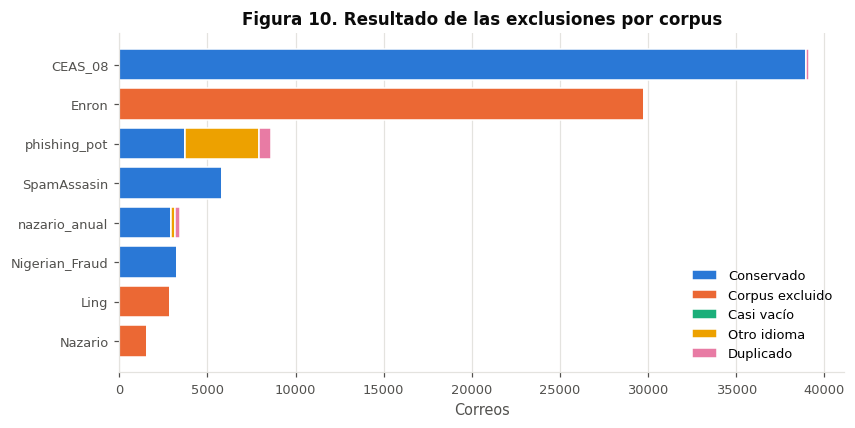

In [6]:
orden = exclusiones.sum(axis=1).sort_values().index
figura, eje = plt.subplots(figsize=(8.5, 4))
izquierda = np.zeros(len(orden))
etiquetas = {"conservado": "Conservado", "grupo_excluido": "Corpus excluido", "casi_vacio": "Casi vacío",
             "idioma": "Otro idioma", "duplicado": "Duplicado"}
for k, motivo in enumerate(exclusiones.columns):
    valores = exclusiones.loc[orden, motivo].to_numpy()
    eje.barh(orden, valores, left=izquierda, color=COLORES_SERIE[k], label=etiquetas[motivo],
             edgecolor="white", linewidth=1)
    izquierda += valores
eje.set_xlabel("Correos")
eje.set_title("Figura 10. Resultado de las exclusiones por corpus")
eje.legend(loc="lower right")
eje.grid(axis="y", visible=False)
guardar_figura(figura, FIGURAS / "fig10_exclusiones.png")
plt.show()

## 4. Dataset final: clase numérica y texto de modelo

`construir_dataset` falla si alguna clase queda con un solo corpus de origen. En Nazario anual se enmascara el
dominio del buzón del autor, que aparecía en una parte de sus correos y delataba la fuente.

In [7]:
datos = dp.construir_dataset(tabla, REGLAS)
composicion = pd.crosstab(datos["grupo"], datos["clase"], margins=True, margins_name="Total")
print(f"Correos en el dataset final: {miles(len(datos))}")
print("Corpus de origen por clase:", datos.groupby("clase")["grupo"].nunique().to_dict())
composicion

Correos en el dataset final: 54.684
Corpus de origen por clase: {'legitimo': 2, 'phishing': 3, 'spam': 2}


clase,legitimo,phishing,spam,Total
grupo,,,,
CEAS_08,17289,0,21674,38963
Nigerian_Fraud,0,3290,0,3290
SpamAssasin,4090,0,1712,5802
nazario_anual,0,2927,0,2927
phishing_pot,0,3702,0,3702
Total,21379,9919,23386,54684


## 5. Particiones y pliegues fuera de distribución

La partición principal es estratificada por clase y corpus (70 % entrenamiento, 15 % validación y 15 %
prueba). Los pliegues fuera de distribución envían a prueba un corpus completo, o el phishing desde 2025, y
conservan la partición del resto; así se mide si el modelo generaliza a fuentes o periodos que no vio.

In [8]:
datos["split"] = dp.particion_estratificada(datos, REGLAS["proporciones"], SEMILLA)
pliegues = dp.pliegues_fuera_de_distribucion(datos, REGLAS["anio_corte_temporal"])
for nombre, fuera in pliegues.items():
    datos[f"fold_{nombre}"] = dp.aplicar_pliegue(datos["split"], fuera)
    datos[f"fuera_{nombre}"] = fuera

particiones = pd.crosstab(datos["split"], datos["clase"]).loc[["train", "val", "test"], CLASES]
tamanos_pliegues = pd.DataFrame({
    nombre: {"fuera_de_distribucion": int(fuera.sum()),
             "entrenamiento_restante": int((datos[f"fold_{nombre}"] == "train").sum())}
    for nombre, fuera in pliegues.items()}).T
display(particiones)
tamanos_pliegues

clase,legitimo,spam,phishing
split,,,
train,14965,16370,6943
val,3207,3508,1488
test,3207,3508,1488


,fuera_de_distribucion,entrenamiento_restante
loso_CEAS_08,38963,11004
loso_Nigerian_Fraud,3290,35975
loso_SpamAssasin,5802,34217
loso_nazario_anual,2927,36229
loso_phishing_pot,3702,35687
temporal_phishing_2025+,2040,36856


**Figura 11.** Tamaño de las particiones por clase y tamaño de cada pliegue fuera de distribución.

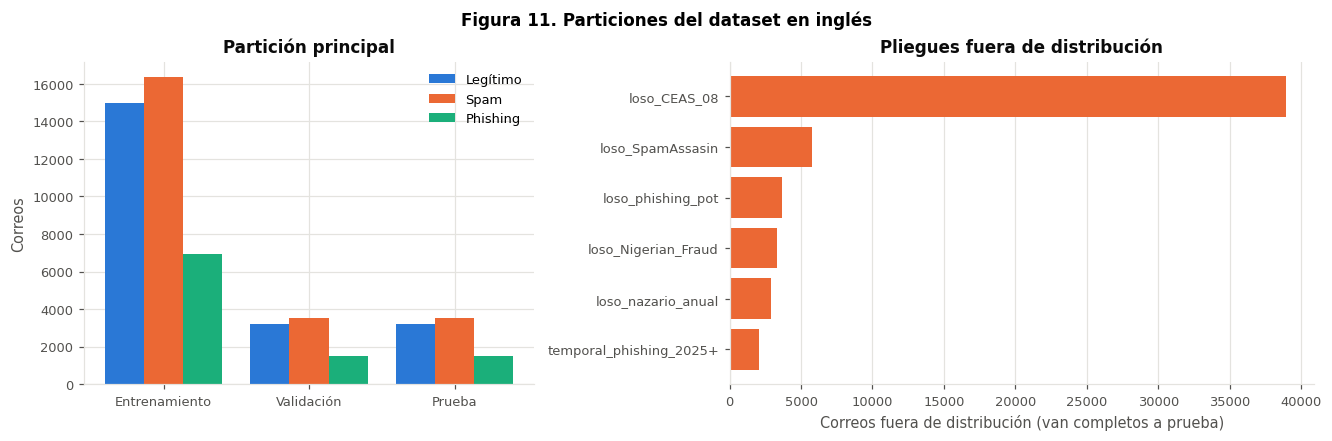

In [9]:
figura, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1, 1.3]},
                                      layout="constrained")
posiciones = np.arange(3)
for k, clase in enumerate(CLASES):
    eje_a.bar(posiciones + (k - 1) * 0.27, particiones[clase], width=0.27, color=COLORES_CLASE[clase],
              label=NOMBRES_CLASE[clase])
eje_a.set_xticks(posiciones, ["Entrenamiento", "Validación", "Prueba"])
eje_a.set_ylabel("Correos")
eje_a.set_title("Partición principal")

orden = tamanos_pliegues.sort_values("fuera_de_distribucion").index
eje_b.barh(orden, tamanos_pliegues.loc[orden, "fuera_de_distribucion"], color=COLORES_SERIE[1])
eje_b.set_xlabel("Correos fuera de distribución (van completos a prueba)")
eje_b.set_title("Pliegues fuera de distribución")
eje_b.grid(axis="y", visible=False)
figura.suptitle("Figura 11. Particiones del dataset en inglés", fontweight="bold", fontsize=11)
eje_a.legend(loc="upper right")
guardar_figura(figura, FIGURAS / "fig11_particiones.png")
plt.show()

## 6. Comprobación de reproducibilidad

Se compara la reconstrucción con el archivo `emails_v1.parquet` que usaron los modelos publicados. Si todo
coincide, el preprocesamiento del repositorio reproduce exactamente los datos de entrenamiento.

In [10]:
publicado = pd.read_parquet(PROCESADOS / "emails_v1.parquet")
columnas_pliegue = sorted(c for c in publicado.columns if c.startswith(("fold_", "fuera_")))
reconstruido = datos.set_index("id")
referencia = publicado.set_index("id")
comunes = reconstruido.index.intersection(referencia.index)

reproduccion = {
    "correos_publicado": int(len(referencia)),
    "correos_reconstruido": int(len(reconstruido)),
    "ids_en_ambos": int(len(comunes)),
    "misma_clase_pct": round(100 * float((reconstruido.loc[comunes, "y"] == referencia.loc[comunes, "y"]).mean()), 3),
    "misma_particion_pct": round(
        100 * float((reconstruido.loc[comunes, "split"] == referencia.loc[comunes, "split"]).mean()), 3),
    "mismo_texto_modelo_pct": round(
        100 * float((reconstruido.loc[comunes, "texto_modelo"] == referencia.loc[comunes, "texto_modelo"]).mean()), 3),
    "mismos_pliegues_pct": round(100 * float(np.mean([
        (reconstruido.loc[comunes, c].astype(str) == referencia.loc[comunes, c].astype(str)).mean()
        for c in columnas_pliegue])), 3),
}
reproduccion["reproduce_exactamente"] = (
    reproduccion["correos_publicado"] == reproduccion["correos_reconstruido"] == reproduccion["ids_en_ambos"]
    and all(reproduccion[k] == 100.0 for k in reproduccion if k.endswith("_pct"))
)
reproduccion

{'correos_publicado': 54684,
 'correos_reconstruido': 54684,
 'ids_en_ambos': 54684,
 'misma_clase_pct': 100.0,
 'misma_particion_pct': 100.0,
 'mismo_texto_modelo_pct': 100.0,
 'mismos_pliegues_pct': 100.0,
 'reproduce_exactamente': True}

La reconstrucción coincide en el 100 % con el archivo publicado: los mismos 54.684 correos, con la misma clase,
la misma partición, el mismo texto de modelo y los mismos pliegues. El preprocesamiento del repositorio
reproduce exactamente los datos con los que se entrenaron los modelos desplegados.

## 7. Controles de seguridad y de fuga de etiqueta

* **IOC vivos.** Ningún texto de modelo puede contener una URL, IP o correo sin defangear.
* **Sonda de fuga.** Porcentaje de correos de cada corpus que contiene términos que delatarían la fuente
  (`dp.TERMINOS_FUGA`). Un valor alto indicaría que el modelo puede reconocer el corpus por esa palabra.
* **Marcadores.** Porcentaje de correos con cada marcador.

In [11]:
con_ioc_vivo = int(publicado["texto_modelo"].map(lambda t: bool(ioc.iocs_vivos(t))).sum())
print("Textos de modelo con IOC vivo:", con_ioc_vivo)

minusculas = publicado["texto_modelo"].str.lower()
sonda = pd.DataFrame({
    termino: minusculas.str.contains(rf"\b{termino}\b", regex=True).groupby(publicado["grupo"]).mean() * 100
    for termino in dp.TERMINOS_FUGA}).round(2)
marcadores = pd.Series({nombre: 100 * publicado["texto_modelo"].str.contains(marca, regex=False).mean()
                        for nombre, marca in dp.MARCADORES.items()}).round(1)
display(sonda.loc[:, (sonda > 0).any()])
marcadores.rename("correos_con_marcador_pct")

Textos de modelo con IOC vivo: 0


,phishing,honeypot,pot,nazario,monkey,enron,spamassassin,ceas,nigerian
grupo,,,,,,,,,
CEAS_08,0.14,0.01,0.09,0.01,0.13,0.00,2.15,0.02,0.03
Nigerian_Fraud,0.00,0.00,0.03,0.00,0.03,0.03,0.00,0.00,7.11
SpamAssasin,0.00,0.03,0.14,0.00,0.16,0.31,9.08,0.00,0.47
nazario_anual,1.95,0.03,0.00,0.14,0.00,0.00,0.00,0.00,0.00
phishing_pot,0.62,0.03,0.11,0.00,0.00,0.00,0.00,0.00,0.00


,correos_con_marcador_pct
url,61.3
ip,2.3
email,32.9
anio,44.9
dominio_propio,1.2


En la corrida de referencia (`notebooks/experimentos/03_preparacion_splits`) solo dos términos superan el 5 %
en un corpus: *nigerian* en Nigerian Fraud (7,1 %) y *spamassassin* en SpamAssassin (9,1 %). El primero es
parte del relato de ese tipo de fraude; el segundo identifica un corpus que aporta legítimo y spam, de modo
que por sí solo no decide entre esas dos clases. Ambos se conservaron y su efecto se mide con los pliegues `loso_Nigerian_Fraud` y
`loso_SpamAssasin`. En cambio, el dominio del buzón del autor de Nazario anual sí se enmascaró, porque solo
identificaba la fuente.

## 8. Manejo del desbalance

No se sobremuestrea ni se generan datos sintéticos en inglés: se usan pesos de clase inversos a la frecuencia
de entrenamiento, y el umbral de phishing se fija por la tasa de falsos positivos en validación.

In [12]:
frecuencias = publicado.loc[publicado["split"] == "train", "y"].value_counts().sort_index()
pesos = (len(publicado[publicado["split"] == "train"]) / (3 * frecuencias)).round(3)
pd.DataFrame({"clase": CLASES, "correos_entrenamiento": frecuencias.values, "peso": pesos.values})

,clase,correos_entrenamiento,peso
0,legitimo,14965,0.853
1,spam,16370,0.779
2,phishing,6943,1.838


## 9. Datos en español

La ruta española se prepara en `notebooks/experimentos/10_datos_es` (SpaPhish y SpearPhishMX: validación de
esquema, idioma, duplicados y conflictos de clase, con la misma partición 70/15/15) y `10b_spam_es_traduccion`
(espejo traducido del corpus inglés con OPUS-MT, que conserva la clase de cada correo y protege los IOC
durante la traducción). El espejo solo se usa para entrenar; la evaluación usa exclusivamente correos nativos.

In [13]:
espanol = pd.read_parquet(PROCESADOS / "emails_es_v2.parquet", columns=["grupo", "clase", "split", "texto_modelo"])
espanol["origen"] = np.where(espanol["grupo"].str.startswith("traducido_"), "traducido", "nativo")
print("IOC vivos en el texto de modelo en español:",
      int(espanol["texto_modelo"].map(lambda t: bool(ioc.iocs_vivos(t))).sum()))
pd.crosstab([espanol["origen"], espanol["split"]], espanol["clase"])

IOC vivos en el texto de modelo en español: 0


clase            legitimo  phishing   spam
origen    split                           
nativo    test        254       387      0
          train      1183      1804      0
          val         254       386      0
traducido test       3163      1463   3004
          train     14758      6827  14018
          val        3162      1463   3004

## 10. Resumen

In [14]:
resumen = {
    "reglas": REGLAS,
    "bitacora_exclusiones": bitacora,
    "correos_dataset_final": int(len(datos)),
    "clase_por_corpus": composicion.drop(index="Total").to_dict(orient="index"),
    "particiones": particiones.to_dict(orient="index"),
    "pliegues": tamanos_pliegues.to_dict(orient="index"),
    "reproduccion": reproduccion,
    "textos_con_ioc_vivo": con_ioc_vivo,
    "marcadores_pct": marcadores.to_dict(),
    "pesos_de_clase": dict(zip(CLASES, pesos.tolist(), strict=True)),
}
(METRICAS / "preprocesamiento_resumen.json").write_text(
    json.dumps(resumen, indent=1, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps({"bitacora": bitacora, "reproduccion": reproduccion, "ioc_vivos": con_ioc_vivo},
                 indent=1, ensure_ascii=False))

{
 "bitacora": {
  "grupo_excluido": 34191,
  "casi_vacio": 30,
  "idioma": 4396,
  "duplicado": 1265
 },
 "reproduccion": {
  "correos_publicado": 54684,
  "correos_reconstruido": 54684,
  "ids_en_ambos": 54684,
  "misma_clase_pct": 100.0,
  "misma_particion_pct": 100.0,
  "mismo_texto_modelo_pct": 100.0,
  "mismos_pliegues_pct": 100.0,
  "reproduce_exactamente": true
 },
 "ioc_vivos": 0
}
